# CSCI 5922 Final Project Code
By Cannon Palmer and Sasidhar Reddy Gangi Reddy

In [ ]:
# Use Google Drive directory
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Imports

In [ ]:
# Imports
import numpy as np
import pandas as pd
import json
import requests

import struct
from array import array
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as T
from torchsummary import summary
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers

# Datasets

## Animal - Master's of Survival (Kaggle)

## Few Shot Big Animal Datset

## Few Shot Non-Animal Dataset

In [ ]:
# Imports
from IPython import get_ipython
from IPython.display import display
from google.colab import drive
drive.mount('/content/drive')
import os, random, zipfile
from collections import defaultdict

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models

from sklearn.metrics import confusion_matrix
import numpy as np
import pandas as pd

!pip install openml
import openml

Mounted at /content/drive
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 160.4/160.4 kB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 95.1/95.1 kB 6.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 37.8 MB/s eta 0:00:00
  Created wheel for liac-arff: filename=liac_arff-2.5.0-py3-none-any.whl size=11717 sha256=f0dbe917d78d80773033145be16d595452e814268e4d832f823543ba9ebd64ce
  Stored in directory: /root/.cache/pip/wheels/00/23/31/5e562fce1f95aabe57f2a7320d07433ba1cd152bcde2f6a002
Successfully built liac-arff


In [ ]:
# Get image name / classification list
# dataset = openml.datasets.get_dataset(44248, download_data=True) # Micro - 800 images
# dataset = openml.datasets.get_dataset(44292, download_data=True) # Mini - 4080 images
dataset = openml.datasets.get_dataset(44326, download_data=True) # Extended - 75221 images

metadata, *_ = dataset.get_data()

print(metadata)

# Count number of unique classes in data
num_classes = metadata['CATEGORY'].nunique()
print("Number of classes in data = " + str(num_classes))

# Get list of classes
classes = metadata['CATEGORY'].unique()
print("")
print("Unique Classes : ")
print(classes)

# Count number of images per unique class
images_per_unique_class = metadata['CATEGORY'].value_counts()
print("")
print("Number of images per unique class")
print(images_per_unique_class)

       FILE_NAME          CATEGORY SUPER_CATEGORY
0      00002.jpg  rice leaf roller           None
1      00003.jpg  rice leaf roller           None
2      00005.jpg  rice leaf roller           None
3      00006.jpg  rice leaf roller           None
4      00008.jpg  rice leaf roller           None
...          ...               ...            ...
75217  75200.jpg      Cicadellidae           None
75218  75213.jpg      Cicadellidae           None
75219  75215.jpg      Cicadellidae           None
75220  75218.jpg      Cicadellidae           None
75221  75220.jpg      Cicadellidae           None

[75222 rows x 3 columns]
Number of classes in data = 102

Unique Classes : 
['rice leaf roller' 'rice leaf caterpillar' 'paddy stem maggot'
 'asiatic rice borer' 'yellow rice borer' 'rice gall midge' 'Rice Stemfly'
 'brown plant hopper' 'white backed plant hopper'
 'small brown plant hopper' 'rice water weevil' 'rice leafhopper'
 'grain spreader thrips' 'rice shell pest' 'grub' 'mole cricket'
 'w

In [ ]:
# Prepare Data
# 2. Paths
ZIP_PATH = "/content/drive/MyDrive/Colab Notebooks/Datasets/insects2_dataset.zip"
EXTRACT_DIR = 'insects2_dataset'
SUBFOLDER = 'processed_images_128'

# 3. Unzip if needed
if not os.path.isdir(EXTRACT_DIR):
    with zipfile.ZipFile(ZIP_PATH, 'r') as z:
        z.extractall(EXTRACT_DIR)

In [ ]:
import csv

def load_csv_column_to_list(file_path, column_index=1):
    column_data = []
    with open(file_path, mode='r', newline='') as csvfile:
        csvreader = csv.reader(csvfile)
        for row in csvreader:
            if len(row) > column_index:
                column_data.append(row[column_index].replace(" ", ""))
    return column_data

# Example usage
file_path = '/content/drive/MyDrive/Colab Notebooks/Datasets/imagenet_classes.txt'
image_net_class_list = load_csv_column_to_list(file_path)
print(image_net_class_list)
len(image_net_class_list)

shared_entries = set(image_net_class_list) & set(classes)
number_of_shared_entries = len(shared_entries)
print("Number of Classes shared with ImageNet = " + str(len(shared_entries)))

print('Percentage of Classes common with ImageNet = ' + str(100*number_of_shared_entries/len(classes)) + "%")

['tench', 'goldfish', 'great_white_shark', 'tiger_shark', 'hammerhead', 'electric_ray', 'stingray', 'cock', 'hen', 'ostrich', 'brambling', 'goldfinch', 'house_finch', 'junco', 'indigo_bunting', 'robin', 'bulbul', 'jay', 'magpie', 'chickadee', 'water_ouzel', 'kite', 'bald_eagle', 'vulture', 'great_grey_owl', 'European_fire_salamander', 'common_newt', 'eft', 'spotted_salamander', 'axolotl', 'bullfrog', 'tree_frog', 'tailed_frog', 'loggerhead', 'leatherback_turtle', 'mud_turtle', 'terrapin', 'box_turtle', 'banded_gecko', 'common_iguana', 'American_chameleon', 'whiptail', 'agama', 'frilled_lizard', 'alligator_lizard', 'Gila_monster', 'green_lizard', 'African_chameleon', 'Komodo_dragon', 'African_crocodile', 'American_alligator', 'triceratops', 'thunder_snake', 'ringneck_snake', 'hognose_snake', 'green_snake', 'king_snake', 'garter_snake', 'water_snake', 'vine_snake', 'night_snake', 'boa_constrictor', 'rock_python', 'Indian_cobra', 'green_mamba', 'sea_snake', 'horned_viper', 'diamondback', 

In [ ]:
# # 7. Few-shot split - Obsolete Code
# def insect2_few_shot_metadata_split(data, classes, n):
#     num_classes = len(classes)
#     train_df = pd.DataFrame(columns=data.columns)
#     # print(data)
#     for i in range(num_classes):
#       temp_df = data[data["CATEGORY"] == classes[i]]
#       temp_df = temp_df.sample(frac=1)
#       for j in range(n):
#         if(j < len(temp_df.index)):
#           train_df.loc[len(train_df.index)] = temp_df.iloc[j]
#     merged_df = data.merge(train_df, on=['FILE_NAME','CATEGORY','SUPER_CATEGORY'], how='left', indicator=True)
#     test_df = merged_df[merged_df['_merge'] == 'left_only'].drop(columns=['_merge'])
#     return train_df, test_df

# few_shot_1_train_metadata, few_shot_1_test_metadata = insect2_few_shot_metadata_split(metadata, classes, 1)
# print(few_shot_1_train_metadata)
# print(few_shot_1_test_metadata)

     FILE_NAME                    CATEGORY SUPER_CATEGORY
0    00570.jpg            rice leaf roller           None
1    01166.jpg       rice leaf caterpillar           None
2    01813.jpg           paddy stem maggot           None
3    02231.jpg          asiatic rice borer           None
4    03006.jpg           yellow rice borer           None
..         ...                         ...            ...
97   68115.jpg        Chlumetia transversa           None
98   68410.jpg  Mango flat beak leafhopper           None
99   68947.jpg  Rhytidodera bowrinii white           None
100  69453.jpg       Sternochetus frigidus           None
101  73524.jpg                Cicadellidae           None

[102 rows x 3 columns]
       FILE_NAME          CATEGORY SUPER_CATEGORY
0      00002.jpg  rice leaf roller           None
1      00003.jpg  rice leaf roller           None
2      00005.jpg  rice leaf roller           None
3      00006.jpg  rice leaf roller           None
4      00008.jpg  rice leaf ro

In [ ]:
import os
import shutil

# Get a list of all image filenames
image_filenames = metadata['FILE_NAME'].to_list()
image_classes = metadata['CATEGORY'].to_list()

source_folder = "insects2_dataset/processed_images_128"
destination_folder = "my_insect_dataset"

# Iterate through images and move them to their respective folders
for i in range (len(image_filenames)):
    image_filename = image_filenames[i]
    image_class = image_classes[i]

    # Create the subfolder for the insect type if it doesn't exist
    insect_folder = os.path.join("my_insect_dataset", image_class)
    os.makedirs(insect_folder, exist_ok=True)

    # Move the image to the subfolder
    source_path = os.path.join(source_folder, image_filename)
    destination_path = os.path.join(insect_folder, image_filename)
    shutil.copy(source_path, destination_path)

# 6. Transforms & Dataset
tf = transforms.Compose([
    transforms.Resize((128,128)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor()
    # ,transforms.Normalize(mean=[0.485, 0.456, 0.406],std=[0.229, 0.224, 0.225])
])
DATA_DIR = "/content/my_insect_dataset"
dataset = datasets.ImageFolder(root=DATA_DIR, transform=tf)

In [ ]:
# few-shot split
def few_shot_split(ds, n):
    cls2inds = {}
    for i,l in enumerate(ds.targets):
        cls2inds.setdefault(l, []).append(i)
    tr, te = [], []
    for inds in cls2inds.values():
        random.shuffle(inds)
        tr += inds[:n]
        te += inds[n:]
    return Subset(ds, tr), Subset(ds, te)

# train & eval
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
loss_fn = nn.CrossEntropyLoss()

def train_model(m, loader, opt, epochs=10):
    m.train()
    for e in range(1, epochs+1):
        tot = 0
        for x,y in loader:
            x,y = x.to(device), y.to(device)
            opt.zero_grad()
            l = loss_fn(m(x), y)
            l.backward()
            opt.step()
            tot += l.item()
        print(f"  Epoch {e}/{epochs} Loss: {tot/len(loader):.4f}")

def eval_model(m, loader):
    m.eval()
    c=t=0
    with torch.no_grad():
        for x,y in loader:
            x,y = x.to(device), y.to(device)
            p = m(x).argmax(1)
            c += (p==y).sum().item()
            t += y.size(0)
    print(f"  Accuracy: {c/t*100:.2f}%")

def print_conf_mat(m, loader):
    m.eval()
    yt, yp = [], []
    with torch.no_grad():
        for x,y in loader:
            x,y = x.to(device), y.to(device)
            p = m(x).argmax(1)
            yt.extend(y.cpu().numpy()); yp.extend(p.cpu().numpy())
    cm = confusion_matrix(yt, yp)
    print("  Confusion Matrix:")
    print(cm)
    print(f"  Accuracy: {np.trace(cm)/cm.sum()*100:.2f}%\n")


In [ ]:
!pip install torchmetrics
from torchmetrics.classification import Accuracy
from torchmetrics.classification import MulticlassAccuracy
from torchmetrics.classification import MulticlassPrecision
from torchmetrics.classification import MulticlassRecall
from torchmetrics.classification import MulticlassConfusionMatrix

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

def eval_metrics(model, test_loader, n_classes):

    # Initialize Accuracy Metrics
    # accuracy_metric = Accuracy(task="multiclass", num_classes=n_classes).to(device)
    accuracy_metric = MulticlassAccuracy(num_classes=n_classes, average='macro').to(device)
    precision_metric = MulticlassPrecision(num_classes=n_classes, average='macro').to(device)
    recall_metric = MulticlassRecall(num_classes=n_classes, average='macro').to(device)

    accuracy_vec_metric = MulticlassAccuracy(num_classes=n_classes, average=None).to(device)
    precision_vec_metric = MulticlassPrecision(num_classes=n_classes, average=None).to(device)
    recall_vec_metric = MulticlassRecall(num_classes=n_classes, average=None).to(device)
    # confusion_metric = MulticlassConfusionMatrix(num_classes=n_classes).to(device)

    # Evaluate on the test set
    model.eval()
    accuracy_metric.reset()
    with torch.no_grad():
        for images, labels in test_loader:

            # # For testing a single batch only
            # dataloader_iterator = iter(test_loader)
            # images, labels = next(dataloader_iterator)

            images, labels = images.to(device), labels.to(device)
            outputs = model(images)

            accuracy_metric.update(outputs, labels)
            precision_metric.update(outputs, labels)
            recall_metric.update(outputs, labels)

            accuracy_vec_metric.update(outputs, labels)
            precision_vec_metric.update(outputs, labels)
            recall_vec_metric.update(outputs, labels)
            # confusion_metric.update(outputs, labels)

    final_test_accuracy = accuracy_metric.compute().item()
    final_test_precision = precision_metric.compute().item()
    final_test_recall = recall_metric.compute().item()

    final_test_vec_accuracy = accuracy_vec_metric.compute()
    final_test_vec_precision = precision_vec_metric.compute()
    final_test_vec_recall = recall_vec_metric.compute()
    # final_test_confusion = confusion_metric.compute()

    print(f"Evaluation results - Test Accuracy: {final_test_accuracy*100:.2f}%")
    print(f"Evaluation results - Test Precision: {final_test_precision*100:.2f}%")
    print(f"Evaluation results - Test Recall: {final_test_recall*100:.2f}%")

    print("Evaluation results - Test Vec Accuracy: ")
    print(final_test_vec_accuracy)
    print("Evaluation results - Test Vec Precision: ")
    print(final_test_vec_precision)
    print("Evaluation results - Test Vec Recall: ")
    print(final_test_vec_recall)
    # fig_, ax_ = confusion_metric.plot()

    metrics_dict = {
        "accuracy": final_test_accuracy,
        "precision": final_test_precision,
        "recall": final_test_recall,
        "accuracy_vec": final_test_vec_accuracy.cpu().numpy().tolist(),
        "precision_vec": final_test_vec_precision.cpu().numpy().tolist(),
        "recall_vec": final_test_vec_recall.cpu().numpy().tolist(),
        # "confusion": final_test_confusion
    }
    return metrics_dict

Using device: cuda


In [ ]:
# === ResNet-50 Few-Shot ===
metric_file_name = "resnet50_insects"

def make_resnet50(nc):
    m = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
    m.fc = nn.Linear(m.fc.in_features, nc)
    for p in m.parameters(): p.requires_grad=False
    for p in m.fc.parameters():    p.requires_grad=True
    return m.to(device)

print(">>> ResNet-50")
metrics_dict = {}
for shot in [1,5,10,20]:
    tr, te = few_shot_split(dataset, shot)
    tl = DataLoader(tr, batch_size=32, shuffle=True)
    el = DataLoader(te, batch_size=32)
    print(f"\n{shot}-shot (train={len(tr)}, test={len(te)})")
    m = make_resnet50(len(dataset.classes))
    opt = optim.Adam(filter(lambda p: p.requires_grad, m.parameters()), lr=1e-3)
    train_model(m, tl, opt, epochs=10)
    # eval_model(m, el)
    metrics_dict_few_shot = eval_metrics(m, el, num_classes)
    metrics_dict[shot] = metrics_dict_few_shot
    # print_conf_mat(m, el)

>>> ResNet-50

1-shot (train=102, test=75120)
  Epoch 1/10 Loss: 4.6883
  Epoch 2/10 Loss: 4.1120
  Epoch 3/10 Loss: 3.6071
  Epoch 4/10 Loss: 3.2903
  Epoch 5/10 Loss: 2.7204
  Epoch 6/10 Loss: 2.3512
  Epoch 7/10 Loss: 2.0218
  Epoch 8/10 Loss: 1.7953
  Epoch 9/10 Loss: 1.4697
  Epoch 10/10 Loss: 1.1473
Evaluation results - Test Accuracy: 8.30%
Evaluation results - Test Precision: 8.91%
Evaluation results - Test Recall: 8.30%
Evaluation results - Test Vec Accuracy: 
tensor([0.0806, 0.0160, 0.0904, 0.0600, 0.0711, 0.0180, 0.0134, 0.3333, 0.0778,
        0.0230, 0.0848, 0.1948, 0.1289, 0.0571, 0.0548, 0.0198, 0.0766, 0.1286,
        0.0319, 0.0017, 0.1673, 0.2003, 0.0249, 0.2935, 0.2226, 0.0102, 0.2969,
        0.4710, 0.2192, 0.1191, 0.4211, 0.1004, 0.0000, 0.0230, 0.0507, 0.0131,
        0.1570, 0.0870, 0.1831, 0.0496, 0.0941, 0.0956, 0.0068, 0.0178, 0.0213,
        0.0420, 0.0550, 0.0227, 0.1070, 0.0107, 0.2228, 0.0000, 0.0332, 0.1187,
        0.0038, 0.0000, 0.0000, 0.0228, 0.0184,

In [ ]:
print(metrics_dict)

import json

# Writing dictionary to a file
output_file_name = "/content/drive/MyDrive/Colab Notebooks/Datasets/" + metric_file_name + ".txt"
with open(output_file_name, 'w') as file:
  file.write(json.dumps(metrics_dict))

{1: {'accuracy': 0.08299168944358826, 'precision': 0.08907391875982285, 'recall': 0.08299168944358826, 'accuracy_vec': [0.08064515888690948, 0.015965167433023453, 0.09043250232934952, 0.05999999865889549, 0.07105263322591782, 0.01796407252550125, 0.01342281885445118, 0.3333333432674408, 0.07782100886106491, 0.02302631549537182, 0.0848214253783226, 0.19483567774295807, 0.1289423257112503, 0.05714285746216774, 0.054794520139694214, 0.01984127052128315, 0.07655502110719681, 0.12857143580913544, 0.03190013766288757, 0.001733102253638208, 0.16726233065128326, 0.20028714835643768, 0.024863438680768013, 0.29347825050354004, 0.22263780236244202, 0.010204081423580647, 0.296875, 0.4709821343421936, 0.21917808055877686, 0.1191067025065422, 0.42105263471603394, 0.10042735189199448, 0.0, 0.023049645125865936, 0.050652340054512024, 0.013071895577013493, 0.15703971683979034, 0.08695652335882187, 0.18312756717205048, 0.049627792090177536, 0.09409190714359283, 0.09560723602771759, 0.006833713036030531,

In [ ]:
# === VGG-16 Few-Shot ===
metric_file_name = "vgg16_insects"

def make_vgg16(nc):
    m = models.vgg16(weights=models.VGG16_Weights.DEFAULT)
    m.classifier[6] = nn.Linear(m.classifier[6].in_features, nc)
    for p in m.features.parameters():       p.requires_grad=False
    for p in m.classifier[6].parameters():  p.requires_grad=True
    return m.to(device)

print(">>> VGG-16")
metrics_dict = {}
for shot in [1,5,10,20]:
    tr, te = few_shot_split(dataset, shot)
    tl = DataLoader(tr, batch_size=32, shuffle=True)
    el = DataLoader(te, batch_size=32)
    print(f"\n{shot}-shot (train={len(tr)}, test={len(te)})")
    m = make_vgg16(len(dataset.classes))
    opt = optim.Adam(filter(lambda p: p.requires_grad, m.parameters()), lr=1e-3)
    train_model(m, tl, opt, epochs=10)
    # eval_model(m, el)
    metrics_dict_few_shot = eval_metrics(m, el, num_classes)
    metrics_dict[shot] = metrics_dict_few_shot
    # print_conf_mat(m, el)


>>> VGG-16

1-shot (train=102, test=75120)


Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth
100%|██████████| 528M/528M [00:04<00:00, 120MB/s]


  Epoch 1/10 Loss: 5.0968
  Epoch 2/10 Loss: 4.6379
  Epoch 3/10 Loss: 3.4367
  Epoch 4/10 Loss: 2.3376
  Epoch 5/10 Loss: 1.7080
  Epoch 6/10 Loss: 1.0252
  Epoch 7/10 Loss: 0.7259
  Epoch 8/10 Loss: 0.3939
  Epoch 9/10 Loss: 0.2092
  Epoch 10/10 Loss: 0.4138
Evaluation results - Test Accuracy: 4.81%
Evaluation results - Test Precision: 13.95%
Evaluation results - Test Recall: 4.81%
Evaluation results - Test Vec Accuracy: 
tensor([0.0129, 0.0377, 0.0157, 0.0200, 0.0211, 0.0599, 0.0067, 0.0385, 0.0233,
        0.0592, 0.0134, 0.0571, 0.0000, 0.0171, 0.0091, 0.0000, 0.0144, 0.1143,
        0.0097, 0.0381, 0.0000, 0.0000, 0.0015, 0.0109, 0.0181, 0.0510, 0.2422,
        0.0446, 0.2740, 0.0521, 0.0526, 0.1111, 0.0000, 0.0053, 0.0000, 0.0000,
        0.0018, 0.0462, 0.1955, 0.1402, 0.0416, 0.0465, 0.0000, 0.0133, 0.0053,
        0.0159, 0.0048, 0.0028, 0.0000, 0.0153, 0.2011, 0.0038, 0.0059, 0.0009,
        0.0741, 0.0000, 0.0000, 0.0945, 0.0127, 0.0000, 0.0100, 0.0168, 0.0047,
        0.13

In [ ]:
print(metrics_dict)

import json

# Writing dictionary to a file
output_file_name = "/content/drive/MyDrive/Colab Notebooks/Datasets/" + metric_file_name + ".txt"
with open(output_file_name, 'w') as file:
  file.write(json.dumps(metrics_dict))

{1: {'accuracy': 0.04808978736400604, 'precision': 0.13951376080513, 'recall': 0.04808978736400604, 'accuracy_vec': [0.012903225608170033, 0.03773584961891174, 0.015727391466498375, 0.019999999552965164, 0.021052632480859756, 0.05988023802638054, 0.00671140942722559, 0.03846153989434242, 0.023346303030848503, 0.05921052768826485, 0.013392857275903225, 0.05712050199508667, 0.0, 0.017142856493592262, 0.00913241971284151, 0.0, 0.014354066923260689, 0.11428571492433548, 0.009708737954497337, 0.03812824934720993, 0.0, 0.0, 0.0015068751526996493, 0.010869565419852734, 0.018110236153006554, 0.051020409911870956, 0.2421875, 0.0446428582072258, 0.27397260069847107, 0.05210918188095093, 0.05263157933950424, 0.1111111119389534, 0.0, 0.005319148767739534, 0.0, 0.0, 0.001805054140277207, 0.04619565233588219, 0.19547325372695923, 0.1401985138654709, 0.041575491428375244, 0.04651162773370743, 0.0, 0.013333333656191826, 0.005319148767739534, 0.01591895893216133, 0.0047846888191998005, 0.00283286115154

In [ ]:
# === ConvNeXt-Base Few-Shot ===
metric_file_name = "convnext_insects"

def make_convnext(nc):
    m = models.convnext_base(weights=models.ConvNeXt_Base_Weights.DEFAULT)
    m.classifier[2] = nn.Linear(m.classifier[2].in_features, nc)
    for p in m.features.parameters():       p.requires_grad=False
    for p in m.classifier[2].parameters():  p.requires_grad=True
    return m.to(device)

print(">>> ConvNeXt-Base")
metrics_dict = {}
for shot in [1,5,10,20]:
    tr, te = few_shot_split(dataset, shot)
    tl = DataLoader(tr, batch_size=32, shuffle=True)
    el = DataLoader(te, batch_size=32)
    print(f"\n{shot}-shot (train={len(tr)}, test={len(te)})")
    m = make_convnext(len(dataset.classes))
    opt = optim.Adam(filter(lambda p: p.requires_grad, m.parameters()), lr=1e-3)
    train_model(m, tl, opt, epochs=10)
    # eval_model(m, el)
    metrics_dict_few_shot = eval_metrics(m, el, num_classes)
    metrics_dict[shot] = metrics_dict_few_shot
    # print_conf_mat(m, el)


>>> ConvNeXt-Base

1-shot (train=102, test=75120)


Downloading: "https://download.pytorch.org/models/convnext_base-6075fbad.pth" to /root/.cache/torch/hub/checkpoints/convnext_base-6075fbad.pth
100%|██████████| 338M/338M [00:07<00:00, 45.6MB/s]


  Epoch 1/10 Loss: 4.7531
  Epoch 2/10 Loss: 4.1471
  Epoch 3/10 Loss: 3.7376
  Epoch 4/10 Loss: 3.3176
  Epoch 5/10 Loss: 3.0868
  Epoch 6/10 Loss: 2.5772
  Epoch 7/10 Loss: 2.3104
  Epoch 8/10 Loss: 1.8429
  Epoch 9/10 Loss: 1.5579
  Epoch 10/10 Loss: 1.4546
Evaluation results - Test Accuracy: 11.95%
Evaluation results - Test Precision: 9.31%
Evaluation results - Test Recall: 11.95%
Evaluation results - Test Vec Accuracy: 
tensor([0.0839, 0.0145, 0.1219, 0.0857, 0.0158, 0.1078, 0.0436, 0.1795, 0.0272,
        0.0230, 0.1027, 0.6260, 0.0629, 0.2514, 0.1872, 0.0238, 0.0574, 0.1714,
        0.0000, 0.0312, 0.1044, 0.7128, 0.0382, 0.0543, 0.0445, 0.0306, 0.1432,
        0.7545, 0.1781, 0.0347, 0.0175, 0.8825, 0.0361, 0.0372, 0.0153, 0.0850,
        0.4404, 0.0842, 0.1235, 0.0012, 0.0963, 0.1576, 0.0046, 0.0267, 0.1809,
        0.0217, 0.0072, 0.0255, 0.0026, 0.1466, 0.0489, 0.2772, 0.0024, 0.0215,
        0.0048, 0.0418, 0.5049, 0.0000, 0.0877, 0.0023, 0.0111, 0.1200, 0.0632,
        0.2

In [ ]:
print(metrics_dict)

import json

# Writing dictionary to a file
output_file_name = "/content/drive/MyDrive/Colab Notebooks/Datasets/" + metric_file_name + ".txt"
with open(output_file_name, 'w') as file:
  file.write(json.dumps(metrics_dict))

{1: {'accuracy': 0.11951149255037308, 'precision': 0.09305763244628906, 'recall': 0.11951149255037308, 'accuracy_vec': [0.08387096971273422, 0.014513787813484669, 0.12188728898763657, 0.08571428805589676, 0.015789473429322243, 0.10778442770242691, 0.043624162673950195, 0.1794871836900711, 0.02723735384643078, 0.02302631549537182, 0.1026785746216774, 0.6259781122207642, 0.06290294229984283, 0.2514285743236542, 0.18721461296081543, 0.02380952425301075, 0.057416267693042755, 0.17142857611179352, 0.0, 0.03119583986699581, 0.10436026006937027, 0.7128499746322632, 0.03823695704340935, 0.054347824305295944, 0.04448818787932396, 0.030612245202064514, 0.1432291716337204, 0.7544642686843872, 0.1780821979045868, 0.034739453345537186, 0.017543859779834747, 0.882478654384613, 0.03614457696676254, 0.03723404183983803, 0.015349194407463074, 0.08496732264757156, 0.44043320417404175, 0.08423913270235062, 0.12345679104328156, 0.001240694778971374, 0.09628009051084518, 0.15762273967266083, 0.004555808845

# Models

## Resnet-50

## VGGNet

## ConvNext

# Finetuning

# Process Results

## Load test results

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

# Prepare Data
# 2. Paths
DATA_FOLDER = "/content/drive/MyDrive/Colab Notebooks/Datasets/CSCI5922_Final_Data/"
FILE_NAMES = ["resnet50_animals","vgg16_animals","convnext_animals",
              "resnet50_flowers","vgg16_flowers","convnext_flowers",
              "resnet50_insects","vgg16_insects","convnext_insects"]

import json

def print_summary(data, name):
  shot = ['1','5','10','20']
  for number in shot:
    print("")
    print(str(name) + " Few Shot Test with " + str(number) + " Samples")
    print(f"  Accuracy: {data[number]['accuracy']*100:.2f}%")
    print(f"  Precision: {data[number]['precision']*100:.2f}%")
    print(f"  Recall: {data[number]['recall']*100:.2f}%")

# Open and read the JSON file
with open(DATA_FOLDER + "resnet50_animals.txt", 'r') as file:
  resnet50_animals = json.load(file)
with open(DATA_FOLDER + "resnet50_flowers.txt", 'r') as file:
  resnet50_flowers = json.load(file)
with open(DATA_FOLDER + "resnet50_insects.txt", 'r') as file:
  resnet50_insects = json.load(file)

with open(DATA_FOLDER + "vgg16_animals.txt", 'r') as file:
  vgg16_animals = json.load(file)
with open(DATA_FOLDER + "vgg16_flowers.txt", 'r') as file:
  vgg16_flowers = json.load(file)
with open(DATA_FOLDER + "vgg16_insects.txt", 'r') as file:
  vgg16_insects = json.load(file)

with open(DATA_FOLDER + "convnext_animals.txt", 'r') as file:
  convnext_animals = json.load(file)
with open(DATA_FOLDER + "convnext_flowers.txt", 'r') as file:
  convnext_flowers = json.load(file)
with open(DATA_FOLDER + "convnext_insects.txt", 'r') as file:
  convnext_insects = json.load(file)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### Accuracy Metrics

In [ ]:
print(" --- ANIMAL Dataset Results --- ")
print_summary(resnet50_animals, "Resnet50 - Animals Dataset -")
print_summary(vgg16_animals, "VGG-16 - Animals Dataset -")
print_summary(convnext_animals, "ConvNext - Animals Dataset -")

 --- ANIMAL Dataset Results --- 

Resnet50 - Animals Dataset - Few Shot Test with 1 Samples
  Accuracy: 42.66%
  Precision: 45.46%
  Recall: 42.66%

Resnet50 - Animals Dataset - Few Shot Test with 5 Samples
  Accuracy: 70.08%
  Precision: 71.96%
  Recall: 70.08%

Resnet50 - Animals Dataset - Few Shot Test with 10 Samples
  Accuracy: 76.84%
  Precision: 78.06%
  Recall: 76.84%

Resnet50 - Animals Dataset - Few Shot Test with 20 Samples
  Accuracy: 81.39%
  Precision: 82.65%
  Recall: 81.39%

VGG-16 - Animals Dataset - Few Shot Test with 1 Samples
  Accuracy: 10.90%
  Precision: 40.79%
  Recall: 10.90%

VGG-16 - Animals Dataset - Few Shot Test with 5 Samples
  Accuracy: 15.64%
  Precision: 32.84%
  Recall: 15.64%

VGG-16 - Animals Dataset - Few Shot Test with 10 Samples
  Accuracy: 16.69%
  Precision: 26.98%
  Recall: 16.69%

VGG-16 - Animals Dataset - Few Shot Test with 20 Samples
  Accuracy: 16.08%
  Precision: 29.76%
  Recall: 16.08%

ConvNext - Animals Dataset - Few Shot Test with 1 

In [ ]:
print(" --- Flower Dataset Results --- ")
print_summary(resnet50_flowers, "Resnet50 - Flowers Dataset -")
print_summary(vgg16_flowers, "VGG-16 - Flowers Dataset -")
print_summary(convnext_flowers, "ConvNext - Flowers Dataset -")

 --- Flower Dataset Results --- 

Resnet50 - Flowers Dataset - Few Shot Test with 1 Samples
  Accuracy: 32.32%
  Precision: 33.11%
  Recall: 32.32%

Resnet50 - Flowers Dataset - Few Shot Test with 5 Samples
  Accuracy: 61.71%
  Precision: 58.78%
  Recall: 61.71%

Resnet50 - Flowers Dataset - Few Shot Test with 10 Samples
  Accuracy: 69.39%
  Precision: 65.99%
  Recall: 69.39%

Resnet50 - Flowers Dataset - Few Shot Test with 20 Samples
  Accuracy: 78.12%
  Precision: 72.99%
  Recall: 78.12%

VGG-16 - Flowers Dataset - Few Shot Test with 1 Samples
  Accuracy: 12.08%
  Precision: 19.60%
  Recall: 12.08%

VGG-16 - Flowers Dataset - Few Shot Test with 5 Samples
  Accuracy: 21.98%
  Precision: 33.80%
  Recall: 21.98%

VGG-16 - Flowers Dataset - Few Shot Test with 10 Samples
  Accuracy: 27.38%
  Precision: 37.40%
  Recall: 27.38%

VGG-16 - Flowers Dataset - Few Shot Test with 20 Samples
  Accuracy: 32.51%
  Precision: 41.36%
  Recall: 32.51%

ConvNext - Flowers Dataset - Few Shot Test with 1 

In [ ]:
print(" --- Insect Dataset Results --- ")
print_summary(resnet50_insects, "Resnet50 - Insects Dataset -")
print_summary(vgg16_insects, "VGG-16 - Insects Dataset -")
print_summary(convnext_insects, "ConvNext - Insects Dataset -")

 --- Insect Dataset Results --- 

Resnet50 - Insects Dataset - Few Shot Test with 1 Samples
  Accuracy: 8.30%
  Precision: 8.91%
  Recall: 8.30%

Resnet50 - Insects Dataset - Few Shot Test with 5 Samples
  Accuracy: 18.68%
  Precision: 14.14%
  Recall: 18.68%

Resnet50 - Insects Dataset - Few Shot Test with 10 Samples
  Accuracy: 24.98%
  Precision: 18.16%
  Recall: 24.98%

Resnet50 - Insects Dataset - Few Shot Test with 20 Samples
  Accuracy: 31.00%
  Precision: 22.61%
  Recall: 31.00%

VGG-16 - Insects Dataset - Few Shot Test with 1 Samples
  Accuracy: 4.81%
  Precision: 13.95%
  Recall: 4.81%

VGG-16 - Insects Dataset - Few Shot Test with 5 Samples
  Accuracy: 9.74%
  Precision: 15.28%
  Recall: 9.74%

VGG-16 - Insects Dataset - Few Shot Test with 10 Samples
  Accuracy: 6.94%
  Precision: 12.50%
  Recall: 6.94%

VGG-16 - Insects Dataset - Few Shot Test with 20 Samples
  Accuracy: 8.24%
  Precision: 9.35%
  Recall: 8.24%

ConvNext - Insects Dataset - Few Shot Test with 1 Samples
  Ac

### Accuracy Plots

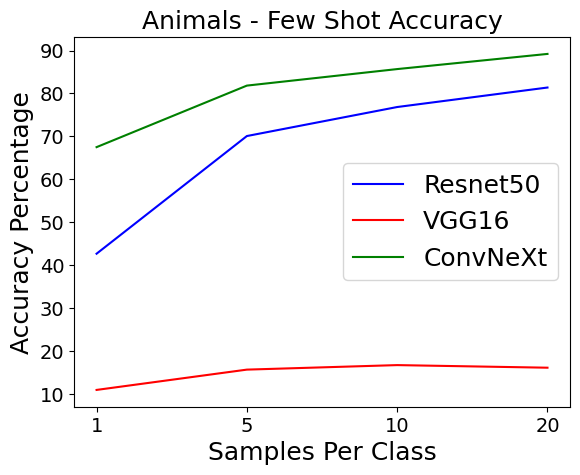

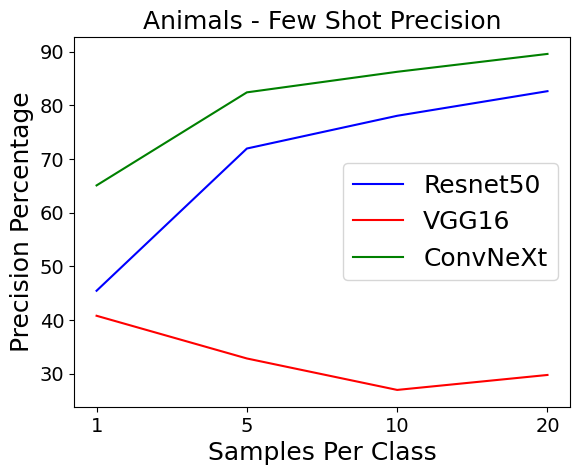

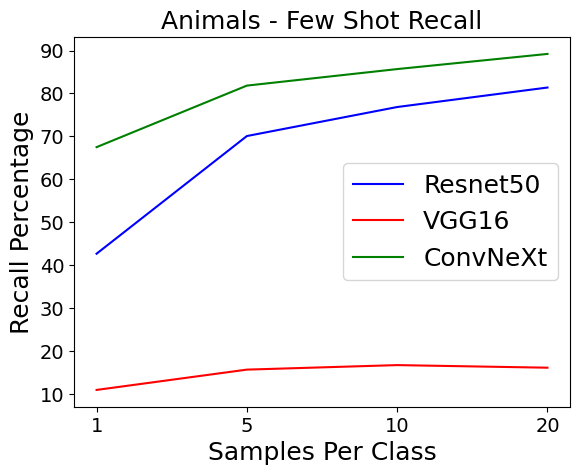

In [ ]:
import matplotlib.pyplot as plt

shot = ['1','5','10','20']
shot_num = [1,5,10,20]

def metric_dict_2_list(data, shot, metric_type):
  output_list = []
  for i in range(len(shot)):
    output_list.insert(len(output_list),100*data[shot[i]][metric_type])
  return output_list

# data = resnet50_animals[shot[3]]
# print(data)
# # plt.figure()
# plt.plot(data['accuracy_vec'],'o')

# Accuracy
metric_type = 'accuracy'
plt.plot(shot, metric_dict_2_list(resnet50_animals, shot, metric_type), color = "blue")
plt.plot(shot, metric_dict_2_list(vgg16_animals, shot, metric_type), color = "red")
plt.plot(shot, metric_dict_2_list(convnext_animals, shot, metric_type), color = "green")
plt.legend(['Resnet50','VGG16','ConvNeXt'], fontsize=18)
plt.xlabel('Samples Per Class', fontsize=18)
plt.ylabel('Accuracy Percentage', fontsize=18)
plt.title('Animals - Few Shot Accuracy', fontsize=18)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)

#Save the figure
plt.savefig("/content/drive/MyDrive/Colab Notebooks/Datasets/AnimalsAccuracy.png", dpi = 300, bbox_inches = "tight")

plt.show()


# Precision
metric_type = 'precision'
plt.plot(shot, metric_dict_2_list(resnet50_animals, shot, metric_type), color = "blue")
plt.plot(shot, metric_dict_2_list(vgg16_animals, shot, metric_type), color = "red")
plt.plot(shot, metric_dict_2_list(convnext_animals, shot, metric_type), color = "green")
plt.legend(['Resnet50','VGG16','ConvNeXt'], fontsize=18)
plt.xlabel('Samples Per Class', fontsize=18)
plt.ylabel('Precision Percentage', fontsize=18)
plt.title('Animals - Few Shot Precision', fontsize=18)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)

# #Save the figure
plt.savefig("/content/drive/MyDrive/Colab Notebooks/Datasets/AnimalsPrecision.png", dpi = 300, bbox_inches = "tight")

plt.show()


# Recall
metric_type = 'recall'
plt.plot(shot, metric_dict_2_list(resnet50_animals, shot, metric_type), color = "blue")
plt.plot(shot, metric_dict_2_list(vgg16_animals, shot, metric_type), color = "red")
plt.plot(shot, metric_dict_2_list(convnext_animals, shot, metric_type), color = "green")
plt.legend(['Resnet50','VGG16','ConvNeXt'], fontsize=18)
plt.xlabel('Samples Per Class', fontsize=18)
plt.ylabel('Recall Percentage', fontsize=18)
plt.title('Animals - Few Shot Recall', fontsize=18)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)

# #Save the figure
plt.savefig("/content/drive/MyDrive/Colab Notebooks/Datasets/AnimalsRecall.png", dpi = 300, bbox_inches = "tight")

plt.show()


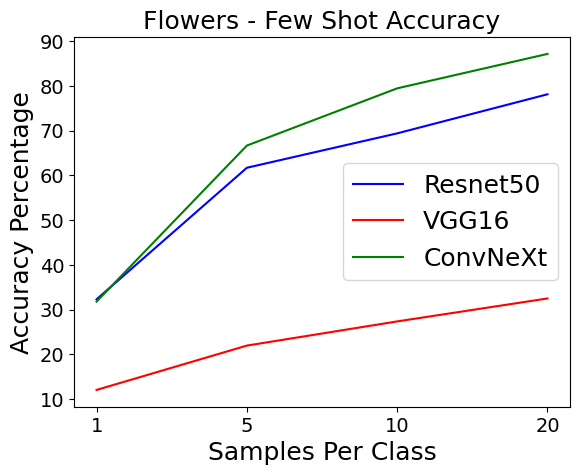

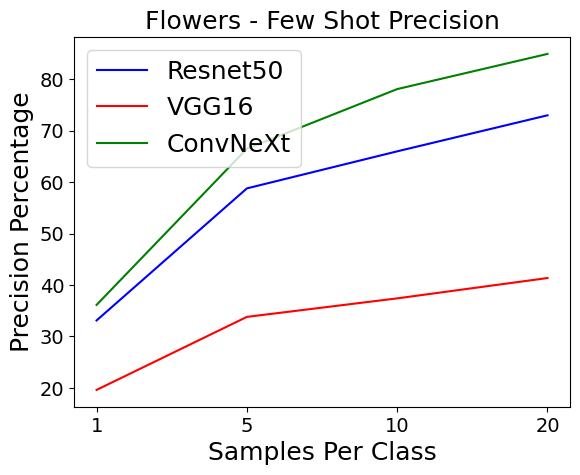

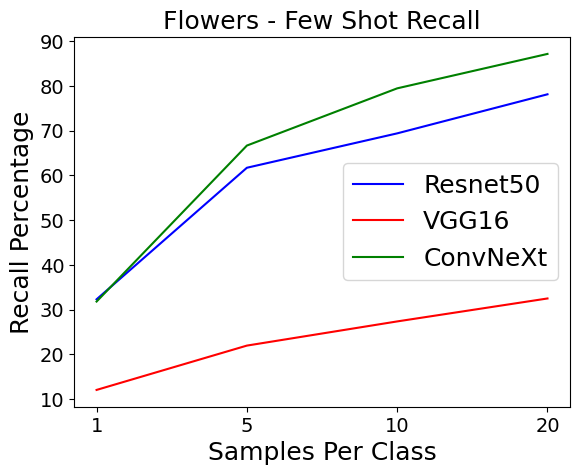

In [ ]:
# Accuracy
metric_type = 'accuracy'
plt.plot(shot, metric_dict_2_list(resnet50_flowers, shot, metric_type), color = "blue")
plt.plot(shot, metric_dict_2_list(vgg16_flowers, shot, metric_type), color = "red")
plt.plot(shot, metric_dict_2_list(convnext_flowers, shot, metric_type), color = "green")
plt.legend(['Resnet50','VGG16','ConvNeXt'], fontsize=18)
plt.xlabel('Samples Per Class', fontsize=18)
plt.ylabel('Accuracy Percentage', fontsize=18)
plt.title('Flowers - Few Shot Accuracy', fontsize=18)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)

# #Save the figure
plt.savefig("/content/drive/MyDrive/Colab Notebooks/Datasets/FlowersAccuracy.png", dpi = 300, bbox_inches = "tight")

plt.show()


# Precision
metric_type = 'precision'
plt.plot(shot, metric_dict_2_list(resnet50_flowers, shot, metric_type), color = "blue")
plt.plot(shot, metric_dict_2_list(vgg16_flowers, shot, metric_type), color = "red")
plt.plot(shot, metric_dict_2_list(convnext_flowers, shot, metric_type), color = "green")
plt.legend(['Resnet50','VGG16','ConvNeXt'], fontsize=18)
plt.xlabel('Samples Per Class', fontsize=18)
plt.ylabel('Precision Percentage', fontsize=18)
plt.title('Flowers - Few Shot Precision', fontsize=18)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)

# #Save the figure
plt.savefig("/content/drive/MyDrive/Colab Notebooks/Datasets/FlowersPrecision.png", dpi = 300, bbox_inches = "tight")

plt.show()


# Recall
metric_type = 'recall'
plt.plot(shot, metric_dict_2_list(resnet50_flowers, shot, metric_type), color = "blue")
plt.plot(shot, metric_dict_2_list(vgg16_flowers, shot, metric_type), color = "red")
plt.plot(shot, metric_dict_2_list(convnext_flowers, shot, metric_type), color = "green")
plt.legend(['Resnet50','VGG16','ConvNeXt'], fontsize=18)
plt.xlabel('Samples Per Class', fontsize=18)
plt.ylabel('Recall Percentage', fontsize=18)
plt.title('Flowers - Few Shot Recall', fontsize=18)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)

# #Save the figure
plt.savefig("/content/drive/MyDrive/Colab Notebooks/Datasets/FlowersRecall.png", dpi = 300, bbox_inches = "tight")

plt.show()


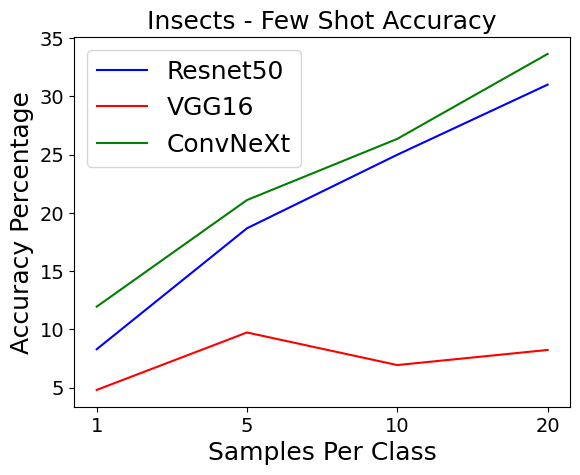

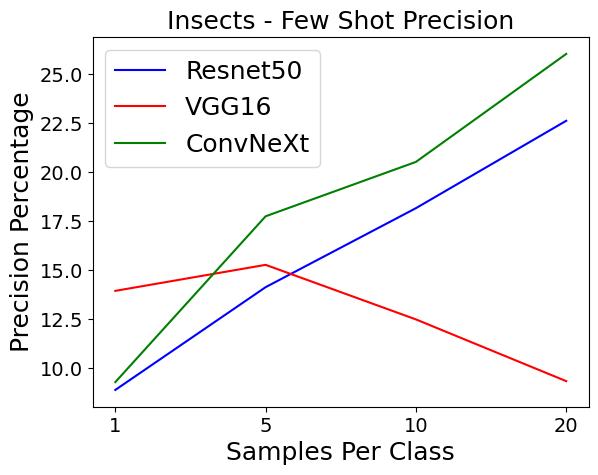

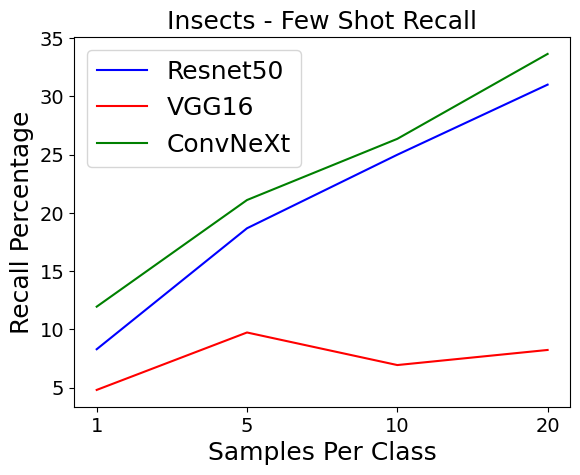

In [ ]:
# Accuracy
metric_type = 'accuracy'
plt.plot(shot, metric_dict_2_list(resnet50_insects, shot, metric_type), color = "blue")
plt.plot(shot, metric_dict_2_list(vgg16_insects, shot, metric_type), color = "red")
plt.plot(shot, metric_dict_2_list(convnext_insects, shot, metric_type), color = "green")
plt.legend(['Resnet50','VGG16','ConvNeXt'], fontsize=18)
plt.xlabel('Samples Per Class', fontsize=18)
plt.ylabel('Accuracy Percentage', fontsize=18)
plt.title('Insects - Few Shot Accuracy', fontsize=18)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)

# #Save the figure
plt.savefig("/content/drive/MyDrive/Colab Notebooks/Datasets/InsectsAccuracy.png", dpi = 300, bbox_inches = "tight")

plt.show()


# Precision
metric_type = 'precision'
plt.plot(shot, metric_dict_2_list(resnet50_insects, shot, metric_type), color = "blue")
plt.plot(shot, metric_dict_2_list(vgg16_insects, shot, metric_type), color = "red")
plt.plot(shot, metric_dict_2_list(convnext_insects, shot, metric_type), color = "green")
plt.legend(['Resnet50','VGG16','ConvNeXt'], fontsize=18)
plt.xlabel('Samples Per Class', fontsize=18)
plt.ylabel('Precision Percentage', fontsize=18)
plt.title('Insects - Few Shot Precision', fontsize=18)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)

# #Save the figure
plt.savefig("/content/drive/MyDrive/Colab Notebooks/Datasets/InsectsPrecision.png", dpi = 300, bbox_inches = "tight")

plt.show()


# Recall
metric_type = 'recall'
plt.plot(shot, metric_dict_2_list(resnet50_insects, shot, metric_type), color = "blue")
plt.plot(shot, metric_dict_2_list(vgg16_insects, shot, metric_type), color = "red")
plt.plot(shot, metric_dict_2_list(convnext_insects, shot, metric_type), color = "green")
plt.legend(['Resnet50','VGG16','ConvNeXt'], fontsize=18)
plt.xlabel('Samples Per Class', fontsize=18)
plt.ylabel('Recall Percentage', fontsize=18)
plt.title('Insects - Few Shot Recall', fontsize=18)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)

# #Save the figure
plt.savefig("/content/drive/MyDrive/Colab Notebooks/Datasets/InsectsRecall.png", dpi = 300, bbox_inches = "tight")

plt.show()

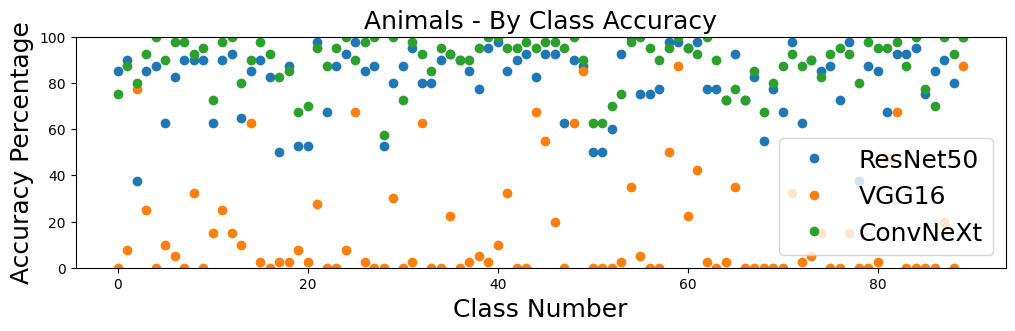

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

def confusion_dict_2_list(data, shot, metric_type):
  output = data[shot][metric_type].copy()
  for i in range(len(output)):
    output[i] = 100 * output[i]
  return output

# Sample data
categories = ['ResNet50', 'VGG16', 'ConvNeXt']
shot = '20'
metric_type = "accuracy_vec"

animal_res = confusion_dict_2_list(resnet50_animals, shot, metric_type)
animal_vgg = confusion_dict_2_list(vgg16_animals, shot, metric_type)
animal_conv = confusion_dict_2_list(convnext_animals, shot, metric_type)

# Number of categories
n = len(animal_res)
ind = np.arange(n)

# # Width of a bar
# width = 0.2

# Plotting the bars
fig, ax = plt.subplots(1,1,figsize=(12, 3))

# bar1 = ax.bar(ind - width, animal_res,  width, label='ResNet50')
# bar2 = ax.bar(ind,         animal_vgg,  width, label='VGG16')
# bar3 = ax.bar(ind + width, animal_conv, width, label='ConvNeXt')

plot1 = ax.plot(ind, animal_res,'o',label='ResNet50')
plot2 = ax.plot(ind, animal_vgg,'o', label='VGG16')
plot3 = ax.plot(ind, animal_conv,'o', label='ConvNeXt')

# Adding labels, title, and legend
ax.set_xlabel('Class Number', fontsize=18)
ax.set_ylabel('Accuracy Percentage', fontsize=18)
ax.set_title('Animals - By Class Accuracy', fontsize=18)
ax.set_ylim([0, 100])
ax.legend(fontsize=18)

plt.savefig("/content/drive/MyDrive/Colab Notebooks/Datasets/AnimalsByClass.png", dpi = 300, bbox_inches = "tight")

# Display the plot
plt.show()

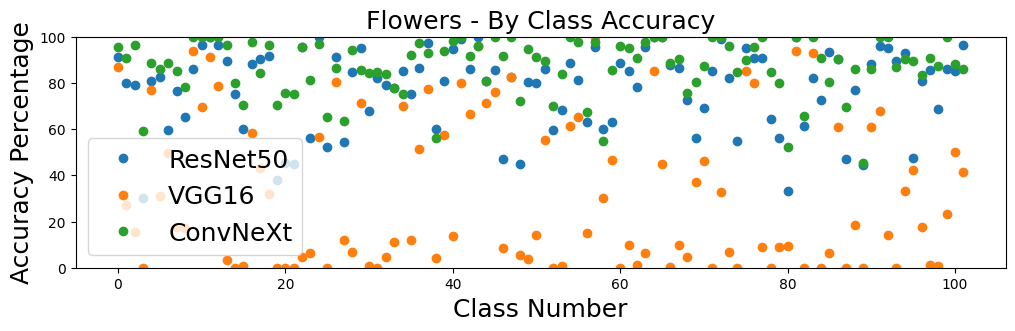

In [ ]:
# Sample data
categories = ['ResNet50', 'VGG16', 'ConvNeXt']
shot = '20'
metric_type = "accuracy_vec"

flower_res = confusion_dict_2_list(resnet50_flowers, shot, metric_type)
flower_vgg = confusion_dict_2_list(vgg16_flowers, shot, metric_type)
flower_conv = confusion_dict_2_list(convnext_flowers, shot, metric_type)

# Number of categories
n = len(flower_res)
ind = np.arange(n)

# # Width of a bar
# width = 0.2

# Plotting the bars
fig, ax = plt.subplots(1,1,figsize=(12, 3))

# bar1 = ax.bar(ind - width, animal_res,  width, label='ResNet50')
# bar2 = ax.bar(ind,         animal_vgg,  width, label='VGG16')
# bar3 = ax.bar(ind + width, animal_conv, width, label='ConvNeXt')

plot1 = ax.plot(ind, flower_res,'o',label='ResNet50')
plot2 = ax.plot(ind, flower_vgg,'o', label='VGG16')
plot3 = ax.plot(ind, flower_conv,'o', label='ConvNeXt')

# plot1 = ax.plot(ind, flower_res,label='ResNet50')
# plot2 = ax.plot(ind, flower_vgg, label='VGG16')
# plot3 = ax.plot(ind, flower_conv, label='ConvNeXt')

# Adding labels, title, and legend
ax.set_xlabel('Class Number', fontsize=18)
ax.set_ylabel('Accuracy Percentage', fontsize=18)
ax.set_title('Flowers - By Class Accuracy', fontsize=18)
ax.set_ylim([0, 100])
ax.legend(fontsize=18)

plt.savefig("/content/drive/MyDrive/Colab Notebooks/Datasets/FlowersByClass.png", dpi = 300, bbox_inches = "tight")

# Display the plot
plt.show()

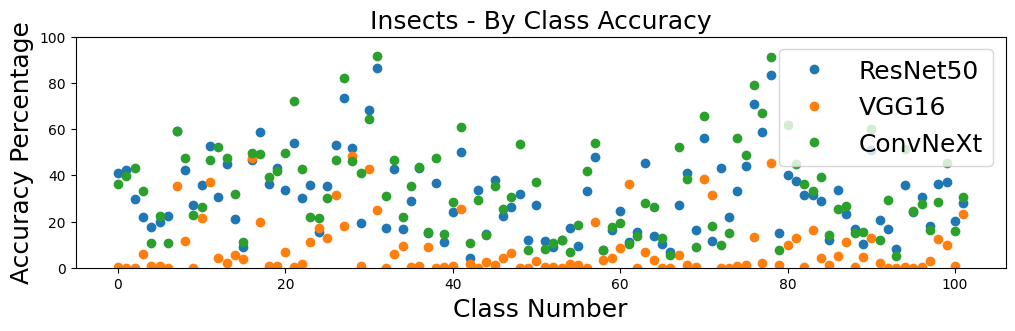

In [ ]:
# Sample data
categories = ['ResNet50', 'VGG16', 'ConvNeXt']
shot = '20'
metric_type = "accuracy_vec"

insect_res = confusion_dict_2_list(resnet50_insects, shot, metric_type)
insect_vgg = confusion_dict_2_list(vgg16_insects, shot, metric_type)
insect_conv = confusion_dict_2_list(convnext_insects, shot, metric_type)

# Number of categories
n = len(insect_res)
ind = np.arange(n)

# # Width of a bar
# width = 0.2

# Plotting the bars
fig, ax = plt.subplots(1,1,figsize=(12, 3))

# bar1 = ax.bar(ind - width, animal_res,  width, label='ResNet50')
# bar2 = ax.bar(ind,         animal_vgg,  width, label='VGG16')
# bar3 = ax.bar(ind + width, animal_conv, width, label='ConvNeXt')

plot1 = ax.plot(ind, insect_res,'o',label='ResNet50')
plot2 = ax.plot(ind, insect_vgg,'o', label='VGG16')
plot3 = ax.plot(ind, insect_conv,'o', label='ConvNeXt')

# Adding labels, title, and legend
ax.set_xlabel('Class Number', fontsize=18)
ax.set_ylabel('Accuracy Percentage', fontsize=18)
ax.set_title('Insects - By Class Accuracy', fontsize=18)
ax.set_ylim([0, 100])
ax.legend(fontsize=18)

plt.savefig("/content/drive/MyDrive/Colab Notebooks/Datasets/InsectsByClass.png", dpi = 300, bbox_inches = "tight")

# Display the plot
plt.show()

## Process Test Results and Plot Graphs

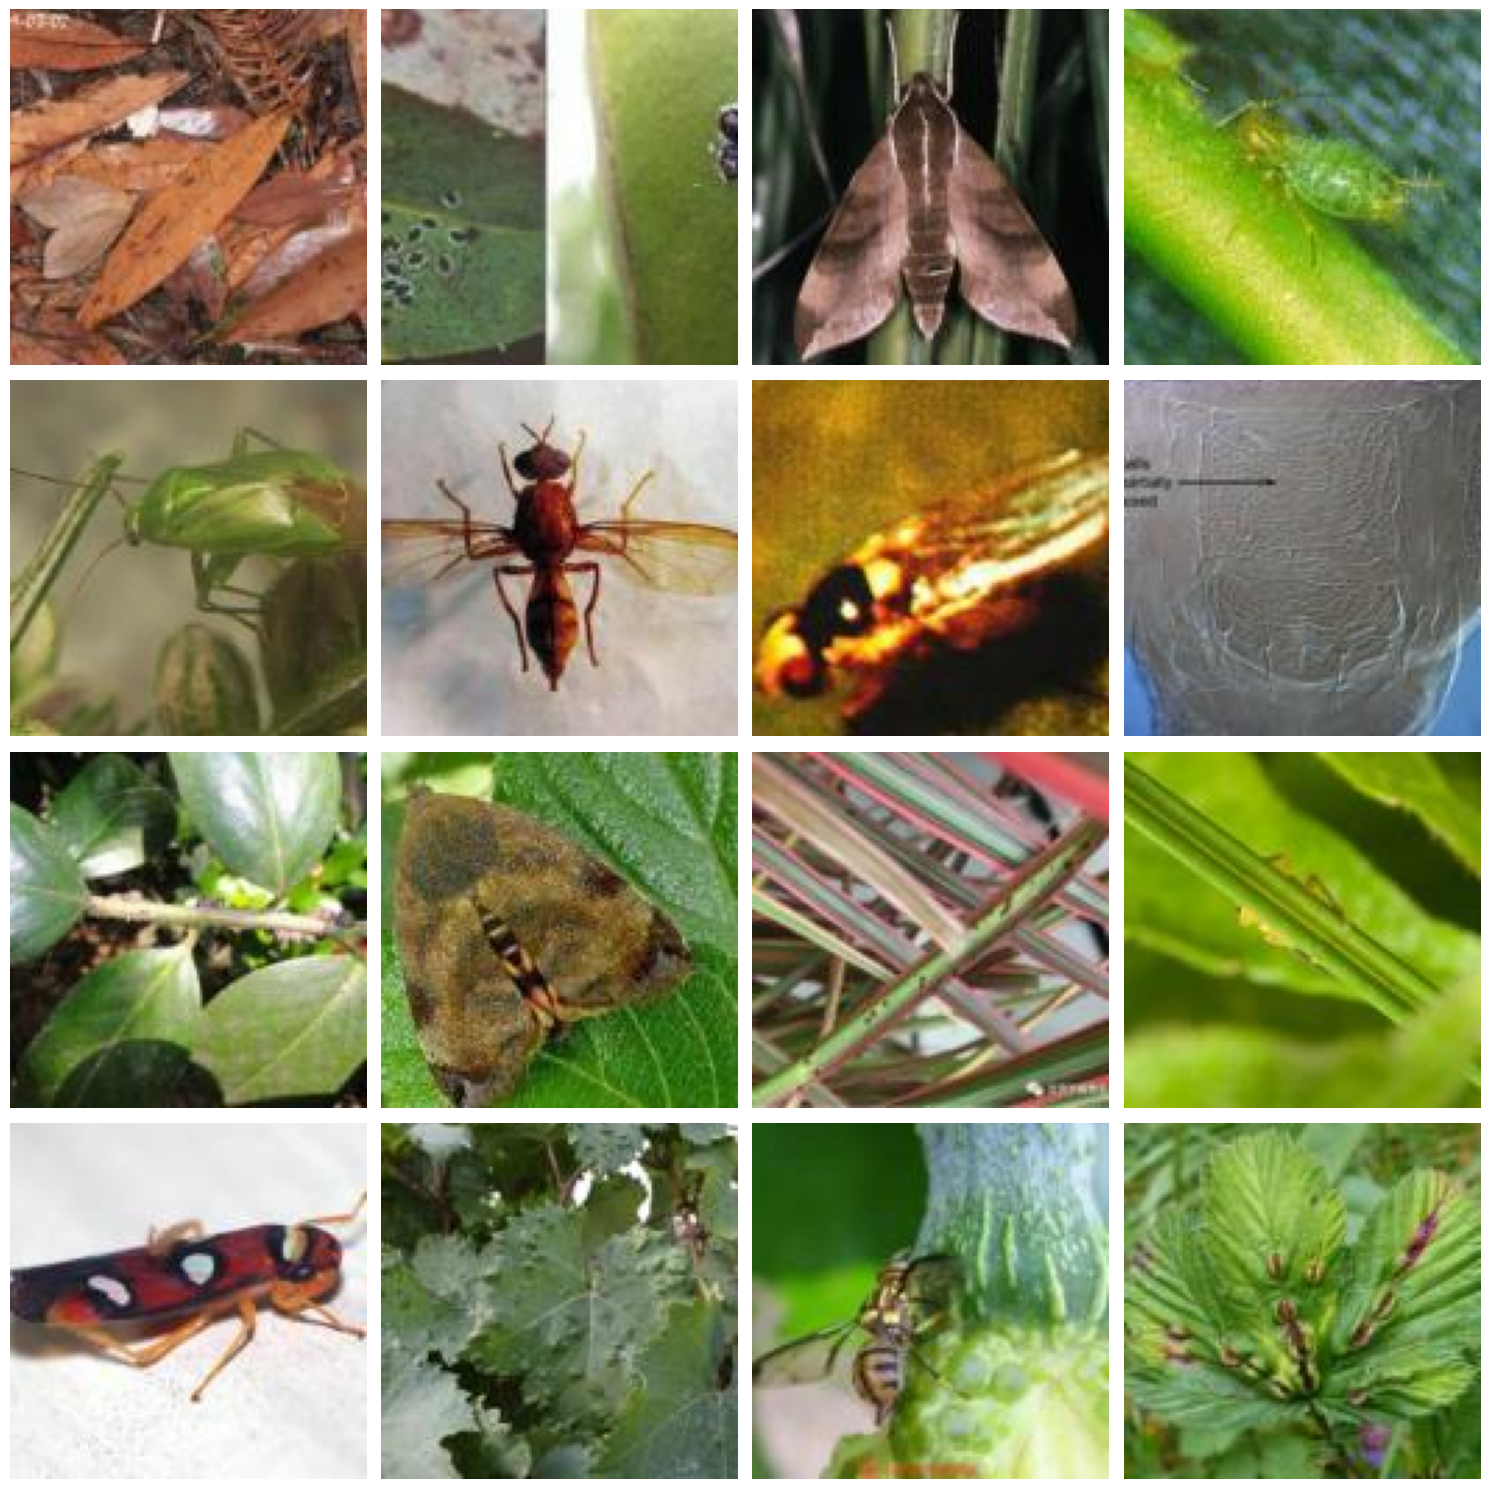

In [ ]:
import matplotlib.pyplot as plt
import os
import math
from IPython.display import display
from PIL import Image
import torch
import torchvision
from torchvision.io import read_image
from torchvision.utils import make_grid

# Get a list of unique class names
class_names = dataset.classes

# Number of classes to display
num_classes_to_display = min(16, len(class_names))

# Calculate rows and columns for a more square grid
num_cols = int(math.ceil(math.sqrt(num_classes_to_display)))
num_rows = int(math.ceil(num_classes_to_display / num_cols))

# Create a figure and axes with calculated rows and columns
fig, axes = plt.subplots(num_rows, num_cols, figsize=(15, 15))  # Adjust figsize as needed
plt.subplots_adjust(left=0, right=1, top=1, bottom=0, wspace=0, hspace=0)

# Flatten the axes array for easier iteration
axes = axes.flatten()
image_list = []
# Iterate through the first 10 classes
for class_index in range(num_classes_to_display):
    class_name = class_names[class_index]
    class_path = os.path.join(DATA_DIR, class_name)

    # Get the first image file in the class folder
    image_file = os.listdir(class_path)[3]
    image_path = os.path.join(class_path, image_file)

    # # Open and display the image
    img = Image.open(image_path)
    axes[class_index].imshow(img)
    # axes[class_index].set_title(class_name)  # Set the title as the class name
    axes[class_index].axis('off')  # Hide axes

    # img = read_image(image_path)
    # image_list.insert(len(image_list),img)

# Adjust spacing between subplots
plt.tight_layout()
plt.savefig("/content/drive/MyDrive/Colab Notebooks/Datasets/InsectsImageGrid.png", dpi = 300, bbox_inches = "tight")

# Show the combined image
plt.show()
# #Save the figure

# print(image_list)
# Grid = make_grid(image_list, nrow=3)
# img = torchvision.transforms.ToPILImage()(Grid)
# img.show()

# OLD Code -Import Kaggle Tank Dataset

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("antoreepjana/military-tanks-dataset-images")

print("Path to dataset files:", path)

Path to dataset files: /root/.cache/kagglehub/datasets/antoreepjana/military-tanks-dataset-images/versions/1


In [ ]:
import os

dataset_path = "/root/.cache/kagglehub/datasets/antoreepjana/military-tanks-dataset-images/versions/1"
extracted_files = os.listdir(dataset_path)
print("Extracted files:", extracted_files)


Extracted files: ['images']


In [ ]:
import os
import matplotlib.pyplot as plt
import cv2
import zipfile

# Get the actual path to the downloaded dataset (assuming it's a zip file)
dataset_zip_path = path[0]

# Extract the zip file
with zipfile.ZipFile(dataset_zip_path, 'r') as zip_ref:
    zip_ref.extractall(os.path.dirname(dataset_zip_path))

# Now, construct the path to the extracted dataset
dataset_path = os.path.join(os.path.dirname(dataset_zip_path), "Military Tanks Dataset")

image_folder = os.path.join(dataset_path, "Military Tanks Dataset")

# Check if the image folder exists before proceeding
if os.path.exists(image_folder):
    sample_image_path = os.path.join(image_folder, os.listdir(image_folder)[0])

    img = cv2.imread(sample_image_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    plt.imshow(img)
    plt.axis("off")
    plt.title("Sample Tank Image")
    plt.show()
else:
    print(f"Error: Image folder not found at {image_folder}")

IsADirectoryError: [Errno 21] Is a directory: '/'

In [ ]:
print(type(path))
from pathlib import Path
directory_path = Path(path)
files = directory_path.iterdir()
for file in files:
    images_repo = file
    print(images_repo)

image1 = images_repo

<class 'str'>
/root/.cache/kagglehub/datasets/antoreepjana/military-tanks-dataset-images/versions/1/images
